
# SaaS Revenue Bridge (MRR / ARR) Analysis

**Domain:** SaaS / Subscription Business Analytics  |  **Role:** Data Analyst  |  **Tools:** Python, pandas, matplotlib, seaborn

**Problem statement:** A subscription software company wants to understand why its monthly recurring revenue (MRR) went up or down. Revenue changes because of new customers, upgrades, downgrades and cancellations. This notebook builds a monthly MRR bridge (waterfall) and the main SaaS metrics: ARR, Net Revenue Retention (NRR), Gross Revenue Retention (GRR) and churn.

**What this notebook does**
1. Creates a subscription dataset (customer, plan, monthly price, start month, cancel month, upgrades and downgrades)
2. Builds a customer x month MRR table
3. Splits every monthly change into New, Expansion, Contraction and Churn
4. Draws the MRR bridge (waterfall) chart
5. Calculates ARR, NRR, GRR, logo churn and ARPA
6. Compares plans and prints insights

In [1]:
!pip install -q pandas matplotlib seaborn

## Step 1: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
np.random.seed(11)
print("libraries ready")

libraries ready


## Step 2: Create the subscription data
Sample SaaS company with 3 plans over 18 months. About 30% of customers already exist in the first month, the rest join later. Some upgrade or downgrade, and some cancel.

In [3]:
months = pd.date_range("2024-07-01", periods=18, freq="MS")
plans = {"Basic": 29, "Pro": 79, "Business": 199}
plan_names = list(plans.keys())
plan_order = ["Basic", "Pro", "Business"]

n_customers = 900
rows = []
for i in range(n_customers):
    customer_id = "C" + str(1000 + i)
    if np.random.rand() < 0.3:
        start_index = 0
    else:
        start_index = np.random.randint(1, 18)
    plan = np.random.choice(plan_names, p=[0.55, 0.33, 0.12])
    rows.append([customer_id, start_index, plan])

customers = pd.DataFrame(rows, columns=["CustomerID", "StartIndex", "StartPlan"])

mrr_matrix = np.zeros((n_customers, 18))
churn_chance = {"Basic": 0.035, "Pro": 0.02, "Business": 0.01}

for i in range(n_customers):
    start = customers.loc[i, "StartIndex"]
    plan = customers.loc[i, "StartPlan"]
    for m in range(start, 18):
        if m > start:
            # churn
            if np.random.rand() < churn_chance[plan]:
                break
            # upgrade or downgrade
            r = np.random.rand()
            idx = plan_order.index(plan)
            if r < 0.03 and idx < 2:
                plan = plan_order[idx + 1]
            elif r > 0.985 and idx > 0:
                plan = plan_order[idx - 1]
        mrr_matrix[i, m] = plans[plan]

mrr = pd.DataFrame(mrr_matrix, columns=months)
mrr.insert(0, "CustomerID", customers["CustomerID"])
mrr = mrr.set_index("CustomerID")

print("Customers:", mrr.shape[0], "| Months:", mrr.shape[1])
mrr.iloc[:5, :8]

Customers: 900 | Months: 18


,2024-07-01 00:00:00,2024-08-01 00:00:00,2024-09-01 00:00:00,2024-10-01 00:00:00,2024-11-01 00:00:00,2024-12-01 00:00:00,2025-01-01 00:00:00,2025-02-01 00:00:00
CustomerID,,,,,,,,
C1000,29.0,29.0,29.0,29.0,29.0,29.0,29.0,29.0
C1001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C1002,29.0,29.0,0.0,0.0,0.0,0.0,0.0,0.0
C1003,0.0,29.0,29.0,29.0,29.0,0.0,0.0,0.0
C1004,0.0,0.0,0.0,29.0,29.0,29.0,29.0,29.0


## Step 3: Total MRR and ARR over time

                         MRR       ARR  Active Customers  ARPA
2024-07-01 00:00:00  15604.0  187248.0               236  66.1
2024-08-01 00:00:00  17919.0  215028.0               261  68.7
2024-09-01 00:00:00  19949.0  239388.0               291  68.6
2024-10-01 00:00:00  23390.0  280680.0               330  70.9
2024-11-01 00:00:00  26173.0  314076.0               367  71.3
2024-12-01 00:00:00  28264.0  339168.0               376  75.2
2025-01-01 00:00:00  30798.0  369576.0               412  74.8
2025-02-01 00:00:00  33089.0  397068.0               441  75.0
2025-03-01 00:00:00  35845.0  430140.0               475  75.5
2025-04-01 00:00:00  37795.0  453540.0               495  76.4
2025-05-01 00:00:00  40989.0  491868.0               521  78.7
2025-06-01 00:00:00  45526.0  546312.0               554  82.2
2025-07-01 00:00:00  48372.0  580464.0               578  83.7
2025-08-01 00:00:00  50279.0  603348.0               601  83.7
2025-09-01 00:00:00  52880.0  634560.0               62

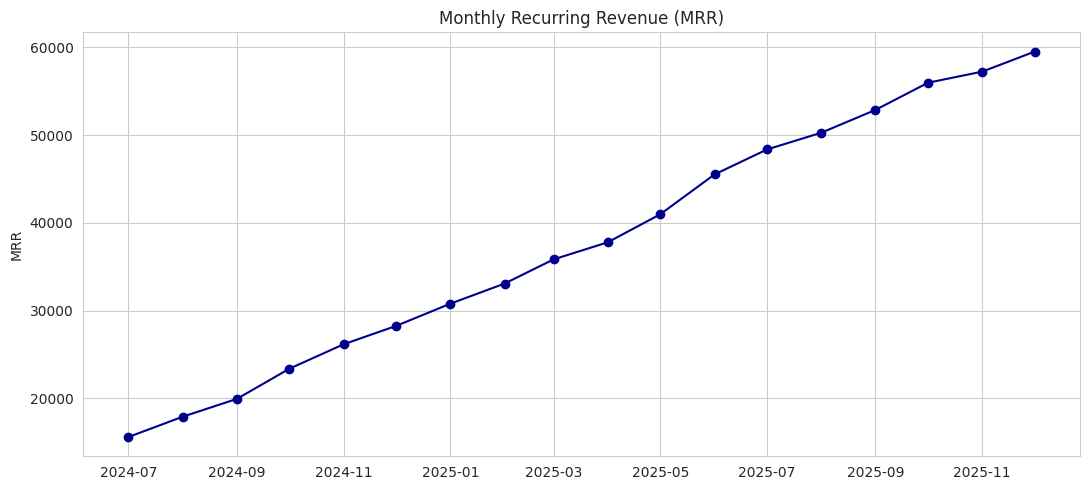

In [4]:
total_mrr = mrr.sum()
active_customers = (mrr > 0).sum()

summary = pd.DataFrame({"MRR": total_mrr, "ARR": total_mrr * 12, "Active Customers": active_customers})
summary["ARPA"] = summary["MRR"] / summary["Active Customers"]
print(summary.round(1))

plt.figure(figsize=(11, 5))
plt.plot(summary.index, summary["MRR"], marker="o", color="darkblue")
plt.title("Monthly Recurring Revenue (MRR)")
plt.ylabel("MRR")
plt.tight_layout()
plt.savefig("mrr_trend.png", dpi=150)
plt.show()

## Step 4: Build the MRR bridge
For every month compared to the month before:
- **New** = customer had 0 last month and pays now
- **Expansion** = customer pays more than last month (upgrade)
- **Contraction** = customer pays less than last month (downgrade)
- **Churn** = customer paid last month and now pays 0

In [5]:
bridge_rows = []
for m in range(1, 18):
    prev = mrr.iloc[:, m - 1]
    curr = mrr.iloc[:, m]

    new_mrr = curr[(prev == 0) & (curr > 0)].sum()
    churn_mrr = -prev[(prev > 0) & (curr == 0)].sum()
    both = (prev > 0) & (curr > 0)
    diff = (curr - prev)[both]
    expansion = diff[diff > 0].sum()
    contraction = diff[diff < 0].sum()

    start_mrr = prev.sum()
    end_mrr = curr.sum()
    bridge_rows.append([months[m], start_mrr, new_mrr, expansion, contraction, churn_mrr, end_mrr])

bridge = pd.DataFrame(bridge_rows, columns=["Month", "Opening MRR", "New", "Expansion", "Contraction", "Churn", "Closing MRR"])

# check: opening + movements should equal closing
bridge["Check"] = bridge["Opening MRR"] + bridge["New"] + bridge["Expansion"] + bridge["Contraction"] + bridge["Churn"] - bridge["Closing MRR"]
print("Bridge check (should be all 0):", bridge["Check"].abs().sum())
bridge = bridge.drop(columns=["Check"])
bridge.round(0)

Bridge check (should be all 0): 0.0


,Month,Opening MRR,New,Expansion,Contraction,Churn,Closing MRR
0,2024-08-01,15604.0,2269.0,440.0,-120.0,-274.0,17919.0
1,2024-09-01,17919.0,2104.0,270.0,-170.0,-174.0,19949.0
2,2024-10-01,19949.0,3333.0,440.0,-50.0,-282.0,23390.0
3,2024-11-01,23390.0,2855.0,800.0,-370.0,-502.0,26173.0
4,2024-12-01,26173.0,2435.0,780.0,-170.0,-954.0,28264.0
5,2025-01-01,28264.0,2916.0,410.0,-170.0,-622.0,30798.0
6,2025-02-01,30798.0,2063.0,900.0,-390.0,-282.0,33089.0
7,2025-03-01,33089.0,3183.0,490.0,-340.0,-577.0,35845.0
8,2025-04-01,35845.0,2743.0,560.0,-220.0,-1133.0,37795.0
9,2025-05-01,37795.0,2991.0,1190.0,-220.0,-767.0,40989.0


## Step 5: Waterfall chart for the full period
Starting MRR (first month) to ending MRR (last month), broken into the four movements.

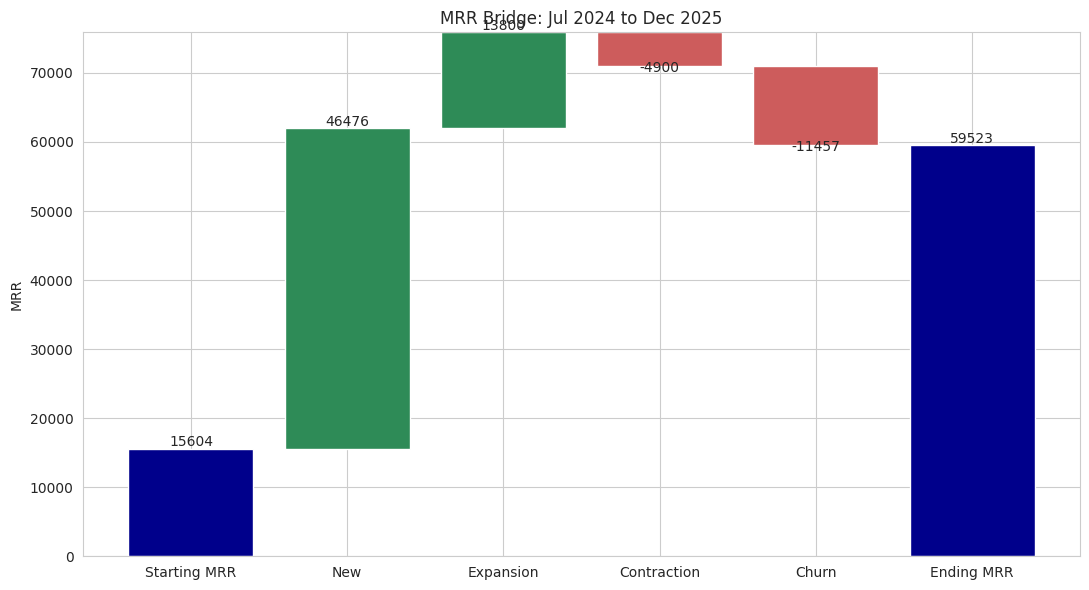

Starting MRR: 15604 | Ending MRR: 59523
Check: 59523 should equal 59523


In [6]:
start_value = mrr.iloc[:, 0].sum()
total_new = bridge["New"].sum()
total_exp = bridge["Expansion"].sum()
total_con = bridge["Contraction"].sum()
total_churn = bridge["Churn"].sum()
end_value = mrr.iloc[:, -1].sum()

labels = ["Starting MRR", "New", "Expansion", "Contraction", "Churn", "Ending MRR"]
values = [start_value, total_new, total_exp, total_con, total_churn, end_value]

plt.figure(figsize=(11, 6))
running = 0
for i in range(len(labels)):
    if i == 0 or i == len(labels) - 1:
        plt.bar(labels[i], values[i], color="darkblue")
        plt.text(i, values[i] + 300, str(int(values[i])), ha="center")
        running = values[i] if i == 0 else running
    else:
        color = "seagreen" if values[i] > 0 else "indianred"
        plt.bar(labels[i], values[i], bottom=running, color=color)
        plt.text(i, running + values[i] + (300 if values[i] > 0 else -900), str(int(values[i])), ha="center")
        running = running + values[i]
plt.title("MRR Bridge: " + months[0].strftime("%b %Y") + " to " + months[-1].strftime("%b %Y"))
plt.ylabel("MRR")
plt.tight_layout()
plt.savefig("mrr_bridge_waterfall.png", dpi=150)
plt.show()

print("Starting MRR:", round(start_value), "| Ending MRR:", round(end_value))
print("Check:", round(start_value + total_new + total_exp + total_con + total_churn), "should equal", round(end_value))

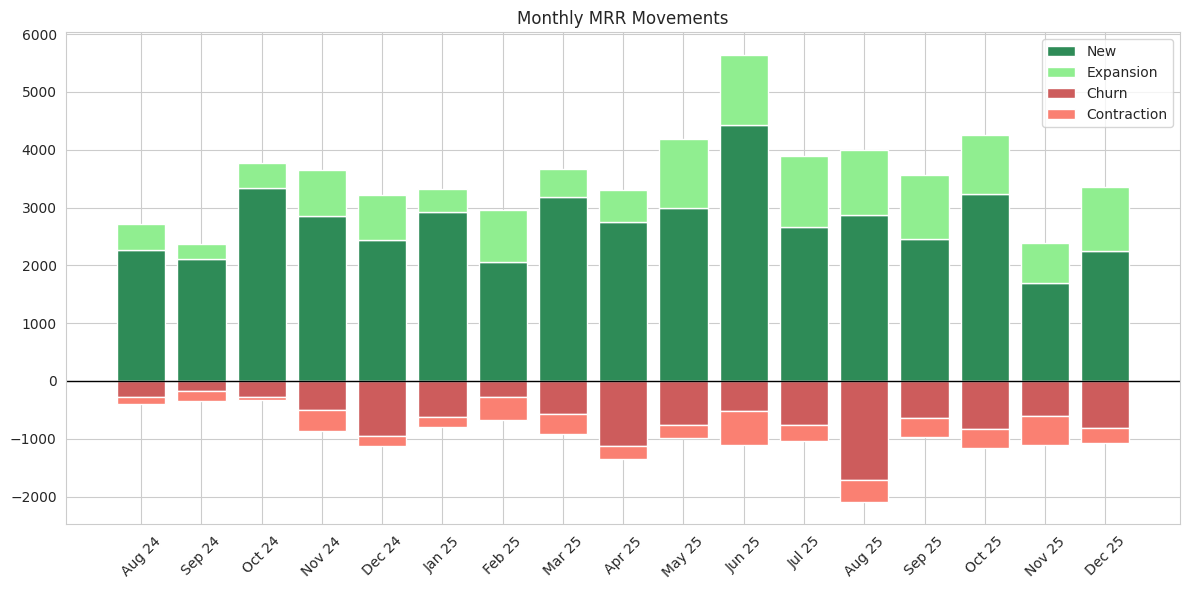

In [7]:
plt.figure(figsize=(12, 6))
x = np.arange(len(bridge))
plt.bar(x, bridge["New"], label="New", color="seagreen")
plt.bar(x, bridge["Expansion"], bottom=bridge["New"], label="Expansion", color="lightgreen")
plt.bar(x, bridge["Churn"], label="Churn", color="indianred")
plt.bar(x, bridge["Contraction"], bottom=bridge["Churn"], label="Contraction", color="salmon")
plt.xticks(x, [m.strftime("%b %y") for m in bridge["Month"]], rotation=45)
plt.axhline(0, color="black", linewidth=1)
plt.title("Monthly MRR Movements")
plt.legend()
plt.tight_layout()
plt.savefig("monthly_mrr_movements.png", dpi=150)
plt.show()

## Step 6: SaaS metrics
- **NRR** (Net Revenue Retention) = (Opening MRR + Expansion + Contraction + Churn) / Opening MRR
- **GRR** (Gross Revenue Retention) = (Opening MRR + Contraction + Churn) / Opening MRR
- **Logo churn** = customers lost / customers at start of the month

     Month  NRR_%  GRR_%  MRR Growth_%  Logo Churn_%
2024-08-01 100.29  97.48         14.84          2.54
2024-09-01  99.59  98.08         11.33          2.30
2024-10-01 100.54  98.34         17.25          2.75
2024-11-01  99.69  96.27         11.90          2.42
2024-12-01  98.69  95.71          7.99          4.36
2025-01-01  98.65  97.20          8.97          2.13
2025-02-01 100.74  97.82          7.44          1.94
2025-03-01  98.71  97.23          8.33          2.95
2025-04-01  97.79  96.23          5.44          3.58
2025-05-01 100.54  97.39          8.45          2.63
2025-06-01 100.25  97.30         11.07          2.50
2025-07-01 100.40  97.72          6.25          2.17
2025-08-01  98.02  95.67          3.94          4.15
2025-09-01 100.30  98.08          5.17          2.16
2025-10-01  99.72  97.79          5.85          2.10
2025-11-01  99.24  98.01          2.26          2.13
2025-12-01 100.07  98.11          3.99          1.62


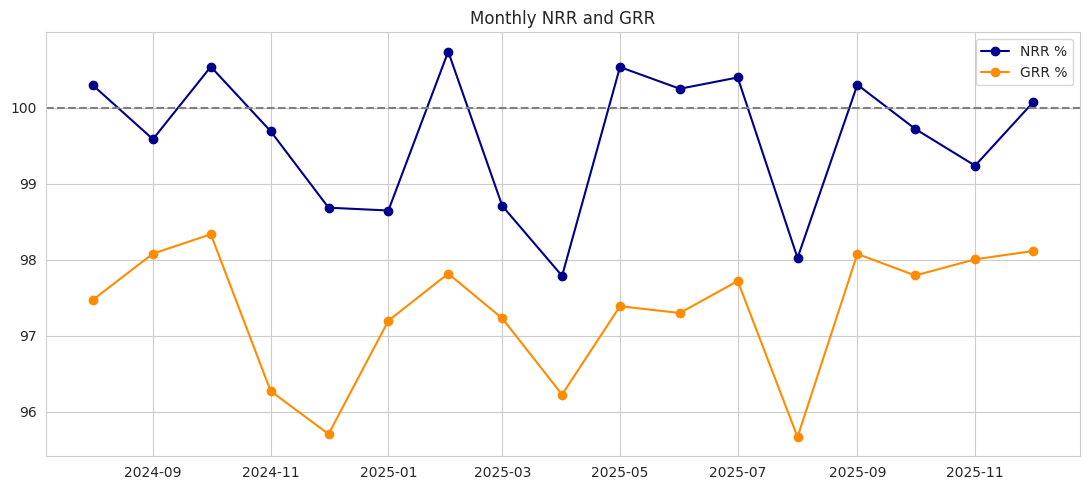

In [8]:
bridge["NRR_%"] = (bridge["Opening MRR"] + bridge["Expansion"] + bridge["Contraction"] + bridge["Churn"]) / bridge["Opening MRR"] * 100
bridge["GRR_%"] = (bridge["Opening MRR"] + bridge["Contraction"] + bridge["Churn"]) / bridge["Opening MRR"] * 100
bridge["MRR Growth_%"] = (bridge["Closing MRR"] - bridge["Opening MRR"]) / bridge["Opening MRR"] * 100

lost_customers = []
for m in range(1, 18):
    prev = mrr.iloc[:, m - 1]
    curr = mrr.iloc[:, m]
    lost = ((prev > 0) & (curr == 0)).sum()
    lost_customers.append(lost / (prev > 0).sum() * 100)
bridge["Logo Churn_%"] = lost_customers

print(bridge[["Month", "NRR_%", "GRR_%", "MRR Growth_%", "Logo Churn_%"]].round(2).to_string(index=False))

plt.figure(figsize=(11, 5))
plt.plot(bridge["Month"], bridge["NRR_%"], marker="o", label="NRR %", color="darkblue")
plt.plot(bridge["Month"], bridge["GRR_%"], marker="o", label="GRR %", color="darkorange")
plt.axhline(100, color="gray", linestyle="--")
plt.title("Monthly NRR and GRR")
plt.legend()
plt.tight_layout()
plt.savefig("nrr_grr_trend.png", dpi=150)
plt.show()

In [9]:
avg_nrr = bridge["NRR_%"].mean()
avg_grr = bridge["GRR_%"].mean()
avg_logo_churn = bridge["Logo Churn_%"].mean()

# annualised numbers
annual_nrr = (avg_nrr / 100) ** 12 * 100
annual_grr = (avg_grr / 100) ** 12 * 100

print("Average monthly NRR:", round(avg_nrr, 2), "%")
print("Average monthly GRR:", round(avg_grr, 2), "%")
print("Average monthly logo churn:", round(avg_logo_churn, 2), "%")
print("Approx annual NRR:", round(annual_nrr, 1), "%")
print("Approx annual GRR:", round(annual_grr, 1), "%")
print("Current ARR:", round(summary['ARR'].iloc[-1]))
print("Current customers:", summary['Active Customers'].iloc[-1])
print("Current ARPA:", round(summary['ARPA'].iloc[-1], 2))

Average monthly NRR: 99.6 %
Average monthly GRR: 97.32 %
Average monthly logo churn: 2.61 %
Approx annual NRR: 95.3 %
Approx annual GRR: 72.2 %
Current ARR: 714276
Current customers: 697
Current ARPA: 85.4


## Step 7: Plan wise view
How many customers and how much MRR each plan has in the last month, and which plan churns the most.

                     Customers    MRR  MRR Share_%  Customer Share_%
2025-12-01 00:00:00                                                 
Basic                      302   8758         14.7              43.3
Pro                        232  18328         30.8              33.3
Business                   163  32437         54.5              23.4

Cancelled customers by their last plan:
          Customers  Cancelled  Cancelled_%
Basic           432        130         30.1
Pro             289         57         19.7
Business        179         16          8.9


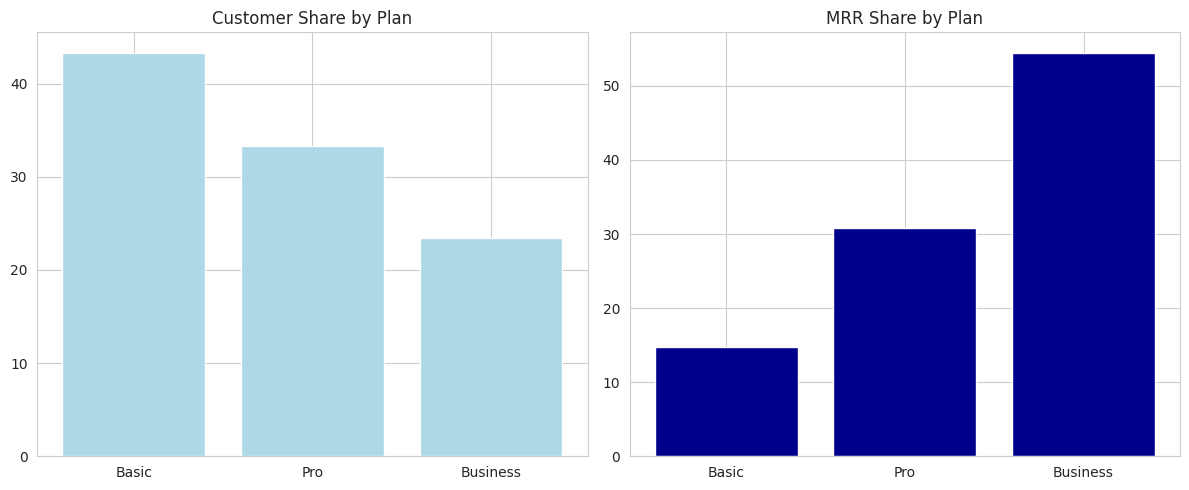

In [10]:
last_month = months[-1]
mrr_last = mrr[last_month]
plan_now = mrr_last[mrr_last > 0].map({29: "Basic", 79: "Pro", 199: "Business"})
plan_table = plan_now.value_counts().reindex(plan_order)
plan_table.name = "Customers"
plan_mrr = plan_table * pd.Series(plans)

plan_summary = pd.DataFrame({"Customers": plan_table, "MRR": plan_mrr})
plan_summary["MRR Share_%"] = plan_summary["MRR"] / plan_summary["MRR"].sum() * 100
plan_summary["Customer Share_%"] = plan_summary["Customers"] / plan_summary["Customers"].sum() * 100
print(plan_summary.round(1))

# churn count by plan (last plan before cancelling)
churn_by_plan = {"Basic": 0, "Pro": 0, "Business": 0}
total_by_plan = {"Basic": 0, "Pro": 0, "Business": 0}
price_to_plan = {29: "Basic", 79: "Pro", 199: "Business"}
for cid in mrr.index:
    row = mrr.loc[cid]
    active = row[row > 0]
    if len(active) == 0:
        continue
    last_plan = price_to_plan[active.iloc[-1]]
    total_by_plan[last_plan] = total_by_plan[last_plan] + 1
    if row.iloc[-1] == 0:
        churn_by_plan[last_plan] = churn_by_plan[last_plan] + 1

churn_df = pd.DataFrame({"Customers": total_by_plan, "Cancelled": churn_by_plan})
churn_df["Cancelled_%"] = churn_df["Cancelled"] / churn_df["Customers"] * 100
print()
print("Cancelled customers by their last plan:")
print(churn_df.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(plan_summary.index, plan_summary["Customer Share_%"], color="lightblue")
axes[0].set_title("Customer Share by Plan")
axes[1].bar(plan_summary.index, plan_summary["MRR Share_%"], color="darkblue")
axes[1].set_title("MRR Share by Plan")
plt.tight_layout()
plt.savefig("plan_mix.png", dpi=150)
plt.show()

## Step 8: Key insights (calculated from the output above)

In [11]:
growth_total = (end_value - start_value) / start_value * 100
biggest_driver = pd.Series({"New": total_new, "Expansion": total_exp}).idxmax()
biggest_loss = pd.Series({"Contraction": total_con, "Churn": total_churn}).idxmin()
best_month = bridge.loc[bridge["MRR Growth_%"].idxmax(), "Month"]
worst_month = bridge.loc[bridge["MRR Growth_%"].idxmin(), "Month"]
highest_churn_plan = churn_df["Cancelled_%"].idxmax()

print("KEY INSIGHTS")
print("-" * 50)
print("1. MRR grew from", round(start_value), "to", round(end_value), "(", round(growth_total, 1), "% in", len(bridge), "months )")
print("2. Current ARR is", round(summary['ARR'].iloc[-1]))
print("3. New customers added", round(total_new), "MRR and expansion added", round(total_exp), "MRR -> biggest growth driver is", biggest_driver)
print("4. Churn removed", round(abs(total_churn)), "MRR and contraction removed", round(abs(total_con)), "MRR -> biggest loss is", biggest_loss)
print("5. Average monthly NRR is", round(avg_nrr, 1), "% and GRR is", round(avg_grr, 1), "%")
print("6. Average monthly logo churn is", round(avg_logo_churn, 2), "%")
print("7. Highest share of cancellations:", highest_churn_plan, "plan (", round(churn_df.loc[highest_churn_plan, 'Cancelled_%'], 1), "% )")
print("8. Best growth month:", best_month.strftime("%b %Y"), "| Weakest month:", worst_month.strftime("%b %Y"))
print()
print("RECOMMENDATIONS")
print("- Focus retention work on the plan with the most cancellations")
print("- Push upgrade offers to Basic customers because expansion revenue is cheap growth")
print("- Watch GRR every month; if it drops, churn is growing faster than the team can add new customers")

KEY INSIGHTS
--------------------------------------------------
1. MRR grew from 15604 to 59523 ( 281.5 % in 17 months )
2. Current ARR is 714276
3. New customers added 46476 MRR and expansion added 13800 MRR -> biggest growth driver is New
4. Churn removed 11457 MRR and contraction removed 4900 MRR -> biggest loss is Churn
5. Average monthly NRR is 99.6 % and GRR is 97.3 %
6. Average monthly logo churn is 2.61 %
7. Highest share of cancellations: Basic plan ( 30.1 % )
8. Best growth month: Oct 2024 | Weakest month: Nov 2025

RECOMMENDATIONS
- Focus retention work on the plan with the most cancellations
- Push upgrade offers to Basic customers because expansion revenue is cheap growth
- Watch GRR every month; if it drops, churn is growing faster than the team can add new customers


In [12]:
bridge.to_csv("mrr_bridge_monthly.csv", index=False)
summary.to_csv("mrr_arr_summary.csv")
plan_summary.to_csv("plan_summary.csv")
print("Saved files:", [f for f in os.listdir(".") if f.endswith(".png") or f.endswith(".csv")])

Saved files: ['plan_mix.png', 'mrr_arr_summary.csv', 'nrr_grr_trend.png', 'mrr_bridge_monthly.csv', 'mrr_trend.png', 'plan_summary.csv', 'monthly_mrr_movements.png', 'mrr_bridge_waterfall.png']


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)

---
*Built by Akshat Kesharwani | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info*